# 03 · Extra experiments

1. **Calibration-set size** (`run_calibration_size`, Adult): Platt and isotonic fitted on stratified subsamples of the calibration set, from 50 to 5,000 examples. Platt has two parameters (high bias, low variance); isotonic is non-parametric (low bias, high variance), so it should need more data.
2. **Training set vs held-out set** (`run_train_vs_heldout`, both datasets): the calibrators fitted on the scores of the training set, which the models have already seen, instead of the calibration set.

The base models are the same as in notebook 02 (same seeds, deterministic training). Outputs: `results/cal_size.csv`, `results/train_vs_heldout.csv`; figures F4 and F5.

In [1]:
# Configuration
SEEDS = range(10)
DATASETS = ("spambase", "adult")  # for the training-set vs held-out experiment
CAL_SIZE_DATASET = "adult"
CAL_SIZES = (50, 100, 200, 500, 1000, 2000, 5000)
RECOMPUTE = True  # False: load the cached results from results/ (about 20 minutes saved)

In [2]:
import logging

import pandas as pd

from calib import plotting
from calib.experiments import run_calibration_size, run_train_vs_heldout
from calib.paths import RESULTS_DIR

# Progress messages from our own code only (other libraries stay at WARNING).
logging.basicConfig(level=logging.WARNING, format="%(name)s: %(message)s", force=True)
logging.getLogger("calib").setLevel(logging.INFO)
logging.getLogger("calib.data").setLevel(logging.WARNING)
pd.set_option("display.precision", 4)
pd.set_option("display.width", 200)

## 1 · Calibration-set size

In [3]:
if RECOMPUTE:
    cal_size = run_calibration_size(dataset=CAL_SIZE_DATASET, sizes=CAL_SIZES, seeds=SEEDS)
else:
    cal_size = pd.read_csv(RESULTS_DIR / "cal_size.csv")
print(f"{len(cal_size)} rows, {cal_size['seed'].nunique()} seeds")

calib.experiments: cal_size: adult seed 0 done in 98.3s


calib.experiments: cal_size: adult seed 1 done in 97.4s


calib.experiments: cal_size: adult seed 2 done in 97.3s


calib.experiments: cal_size: adult seed 3 done in 504.0s


calib.experiments: cal_size: adult seed 4 done in 33.1s


...

calib.experiments: cal_size: adult seed 6 done in 39.4s


calib.experiments: cal_size: adult seed 7 done in 41.3s


calib.experiments: cal_size: adult seed 8 done in 40.8s


calib.experiments: cal_size: adult seed 9 done in 41.6s


300 rows, 10 seeds


Mean test metric over seeds, per calibration-set size (size 0 = uncalibrated). The subsample sizes can differ from the nominal ones by one example per class, due to rounding.

In [4]:
pd.concat({metric: cal_size.pivot_table(index="cal_size", columns=["model", "method"], values=metric)
           for metric in ["log_loss", "brier", "ece"]}, axis=1)

log_loss                                                       brier                                                         ece                                                   
model      logreg                            rf                        logreg                            rf                        logreg                            rf                     
method   isotonic   platt uncalibrated isotonic   platt uncalibrated isotonic   platt uncalibrated isotonic   platt uncalibrated isotonic   platt uncalibrated isotonic   platt uncalibrated
cal_size                                                                                                                                                                                    
0             NaN     NaN       0.3253      NaN     NaN       0.3106      NaN     NaN       0.1041      NaN     NaN       0.0979      NaN     NaN       0.0109      NaN     NaN       0.0244
50         1.4149  0.3376          NaN   1.4190  0.3217          NaN   0.1165  0.1073          NaN   0.1112  0.1013          NaN   0.0609  0.0413          NaN   0.0666  0.0468          NaN
100        0.9146  0.3323          NaN   0.8525  0.3120          NaN   0.1113  0.1059          NaN   0.1032  0.0984          NaN   0.0476  0.0325          NaN   0.0386  0.0279          NaN
200        0.5094  0.3280          NaN   0.5025  0.3090          NaN   0.1088  0.1047          NaN   0.1016  0.0976          NaN   0.0359  0.0223          NaN   0.0354  0.0210          NaN
500        0.4291  0.3273          NaN   0.4074  0.3077          NaN   0.1068  0.1045          NaN   0.0994  0.0972          NaN   0.0241  0.0187          NaN   0.0232  0.0148          NaN
1000       0.3749  0.3266          NaN   0.3606  0.3075          NaN   0.1056  0.1043          NaN   0.0987  0.0973          NaN   0.0207  0.0172          NaN   0.0209  0.0154          NaN
2000       0.3497  0.3255          NaN   0.3284  0.3067          NaN   0.1047  0.1041          NaN   0.0977  0.0971          NaN   0.0157  0.0118          NaN   0.0162  0.0129          NaN
5000       0.3361  0.3253          NaN   0.3207  0.3065          NaN   0.1044  0.1041          NaN   0.0974  0.0970          NaN   0.0126  0.0107          NaN   0.0117  0.0124          NaN

Isotonic predictions of exactly 0 or 1 on the test set (mean per seed), and how many of them are wrong:

In [5]:
iso = cal_size[cal_size["method"] == "isotonic"]
iso.pivot_table(index="cal_size", columns="model", values=["n_exact_01", "n_exact_01_wrong"])

n_exact_01         n_exact_01_wrong       
model        logreg      rf           logreg     rf
cal_size                                           
50           5461.5  5548.1            307.2  312.6
100          4480.6  5027.1            167.5  156.5
200          3282.0  3389.8             50.6   54.6
500          2383.9  2785.6             28.9   28.7
1000         1997.8  2142.5             13.9   15.1
2000         1514.6  1494.9              6.9    6.2
5000          970.3  1556.9              3.1    4.4

## F4 · Test metrics vs calibration-set size

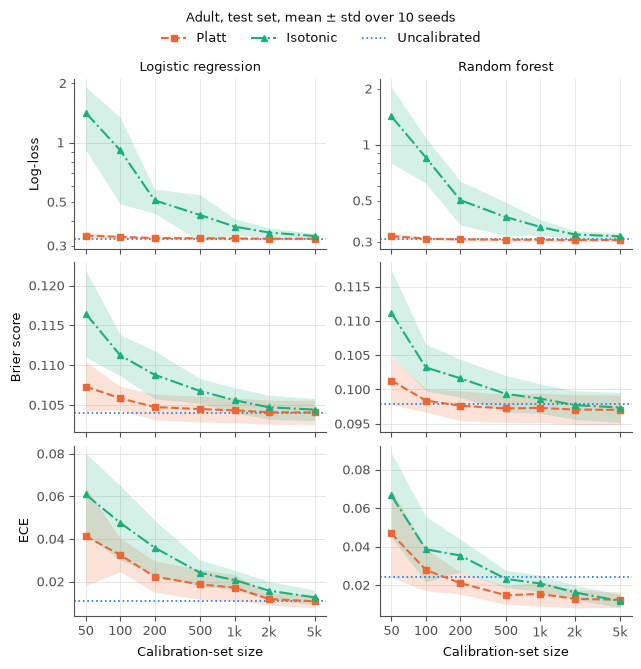

In [6]:
plotting.plot_calibration_size();

## 2 · Calibrators fitted on the training set vs on a held-out set

In [7]:
if RECOMPUTE:
    train_vs_heldout = run_train_vs_heldout(datasets=DATASETS, seeds=SEEDS)
else:
    train_vs_heldout = pd.read_csv(RESULTS_DIR / "train_vs_heldout.csv")
print(f"{len(train_vs_heldout)} rows, {train_vs_heldout['seed'].nunique()} seeds")

calib.experiments: train_vs_heldout: spambase seed 0 done in 14.2s


calib.experiments: train_vs_heldout: spambase seed 1 done in 13.8s


calib.experiments: train_vs_heldout: spambase seed 2 done in 13.8s


calib.experiments: train_vs_heldout: spambase seed 3 done in 14.0s


calib.experiments: train_vs_heldout: spambase seed 4 done in 13.8s


...

calib.experiments: train_vs_heldout: adult seed 6 done in 42.2s


calib.experiments: train_vs_heldout: adult seed 7 done in 43.2s


calib.experiments: train_vs_heldout: adult seed 8 done in 42.6s


calib.experiments: train_vs_heldout: adult seed 9 done in 41.7s


200 rows, 10 seeds


Mean ± std over seeds of the test metrics, by where the calibrator was fitted:

In [8]:
metrics = ["log_loss", "brier", "ece", "n_exact_01_wrong"]
stats = train_vs_heldout.groupby(["dataset", "model", "method", "fit_on"], sort=False)[metrics].agg(["mean", "std"])
stats

log_loss           brier             ece         n_exact_01_wrong         
                                        mean     std    mean     std    mean     std             mean      std
dataset  model  method       fit_on                                                                           
spambase logreg platt        train    0.2512  0.0253  0.0635  0.0043  0.0342  0.0055              0.1   0.3162
                isotonic     train    0.2830  0.0488  0.0623  0.0046  0.0259  0.0073              1.9   1.2867
                uncalibrated cal      0.2485  0.0232  0.0639  0.0041  0.0349  0.0051              0.1   0.3162
                platt        cal      0.2481  0.0178  0.0660  0.0033  0.0413  0.0085              0.0   0.0000
                isotonic     cal      0.3006  0.0733  0.0623  0.0042  0.0227  0.0047              2.5   2.1213
         rf     platt        train    0.1791  0.0360  0.0411  0.0050  0.0258  0.0048              0.0   0.0000
                isotonic     train    1.3772  0.7890  0.0515  0.0085  0.0462  0.0147             35.6  22.5989
                uncalibrated cal      0.1726  0.0143  0.0451  0.0040  0.0533  0.0101              0.0   0.0000
                platt        cal      0.1544  0.0199  0.0407  0.0042  0.0195  0.0058              0.0   0.0000
                isotonic     cal      0.2035  0.0778  0.0412  0.0045  0.0170  0.0063              1.7   2.0575
adult    logreg platt        train    0.3253  0.0042  0.1041  0.0016  0.0103  0.0028              0.0   0.0000
                isotonic     train    0.3277  0.0058  0.1042  0.0016  0.0103  0.0038              0.7   0.9487
                uncalibrated cal      0.3253  0.0041  0.1041  0.0016  0.0109  0.0031              0.0   0.0000
                platt        cal      0.3253  0.0041  0.1040  0.0015  0.0110  0.0031              0.0   0.0000
                isotonic     cal      0.3292  0.0046  0.1043  0.0014  0.0109  0.0039              1.1   0.9944
         rf     platt        train    0.3188  0.0079  0.0991  0.0027  0.0353  0.0041              0.0   0.0000
                isotonic     train    0.4864  0.0233  0.0985  0.0025  0.0317  0.0035             51.8   6.4601
                uncalibrated cal      0.3106  0.0047  0.0979  0.0019  0.0244  0.0043              0.0   0.0000
                platt        cal      0.3064  0.0056  0.0970  0.0022  0.0119  0.0041              0.0   0.0000
                isotonic     cal      0.3131  0.0120  0.0971  0.0021  0.0103  0.0028              2.2   2.0440

Fitted Platt slope and number of isotonic blocks, by where the calibrator was fitted (mean over seeds):

In [9]:
train_vs_heldout.groupby(["dataset", "model", "fit_on"], sort=False)[["platt_a", "platt_b", "iso_blocks"]].mean()

platt_a  platt_b  iso_blocks
dataset  model  fit_on                              
spambase logreg train    1.0694   0.0226        24.6
                cal      0.8444  -0.1069        17.6
         rf     train    2.6906   0.3754         6.3
                cal      1.5260   0.0453        15.0
adult    logreg train    1.0194   0.0122        70.5
                cal      0.9866  -0.0217        44.7
         rf     train    1.7473   0.3519        54.9
                cal      1.2288   0.1099        42.9

## F5 · Training-set vs held-out calibration

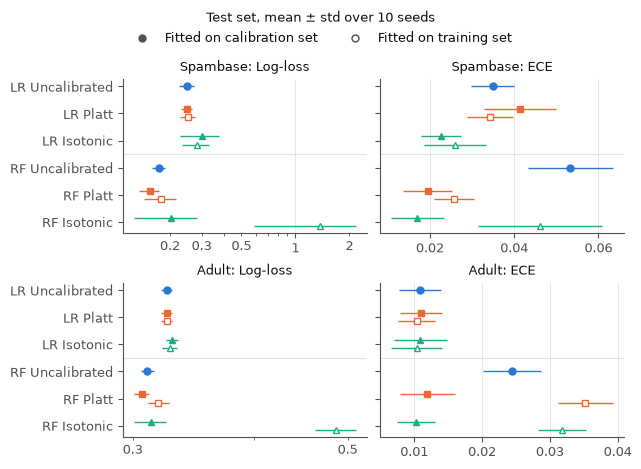

In [10]:
plotting.plot_train_vs_heldout();

## Observations

**Calibration-set size (F4): Platt wins at every size; no crossover up to 5,000 examples.** Platt has a lower log-loss than isotonic on every seed at every size, and a lower Brier score on all but at most one seed per size. On ECE Platt has the lower mean at every size except for RF at 5,000 examples (0.0117 isotonic vs 0.0124 Platt, isotonic better on 4 of 10 seeds). The expected crossover (isotonic overtaking Platt once the calibration set is large) does not appear in this range. With the full calibration set of 9,044 examples (notebook 02), isotonic is ahead of Platt only on RF's ECE (0.0103 vs 0.0119), while Platt keeps the better log-loss and Brier score.

**The variance of isotonic regression is the visible effect.** With 50 examples, more than half of the 9,045 test predictions of isotonic are exactly 0 or 1 (about 5,500), and about 310 of them are wrong, which gives a log-loss of 1.4 for both models. The gap closes steadily as the calibration set grows (isotonic log-loss 1.41 → 0.336 for LR and 1.42 → 0.321 for RF from 50 to 5,000 examples), while Platt is almost flat: its two parameters are already well estimated with a few hundred examples.

**Why no crossover here?** Platt can only win at large sizes if its bias is small, i.e. if the true correction is close to a sigmoid in the score. With the score defined as the logit of the RF probability, the correction needed on Adult is close to linear in the score (F2: the binned calibration-set frequencies lie close to the Platt curve), so the extra flexibility of isotonic buys little and costs variance. This is our interpretation of the result, not something the experiment tests directly.

**Calibrating with very little data can hurt.** For LR, which is already calibrated, any calibrator fitted on 50–100 examples is worse than no calibration on every metric (e.g. ECE 0.041 with Platt at 50 examples vs 0.011 uncalibrated). For RF, Platt beats the uncalibrated model on mean log-loss and ECE only from 200 examples on.

**Training set vs held-out set (F5): a held-out set is essential for RF, much less so for LR.** For RF, fitting either calibrator on the training scores gives a worse test log-loss on every seed of both datasets. RF's training-set probabilities are more confident and more often right than its test predictions, so the calibrator learns the wrong correction:
- Platt over-stretches: a = 2.69 on Spambase and 1.75 on Adult when fitted on the training set, against 1.53 and 1.23 on the calibration set.
- Isotonic collapses to a few pure blocks (6.3 blocks on average on Spambase, as few as 2): on Spambase, 810 of the 921 test predictions become exactly 0 or 1, about 36 of them wrong, and the log-loss rises to 1.38 (0.20 with the held-out set). On Adult, RF's ECE with training-set isotonic (0.032) is worse than with no calibration (0.024).

For LR the two choices give almost the same result (mean Platt slope 1.07 on Spambase and 1.02 on Adult when fitted on the training set): a regularized linear model barely overfits its training scores, so they are nearly as good as held-out scores for calibration. The held-out set matters for flexible models like RF.
